In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
df = pd.read_csv('train.csv')

In [ ]:
df.shape

(1142, 785)

In [ ]:
df.head(3)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
x = df.iloc[:,1:].values
y = df['label'].values

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=2)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

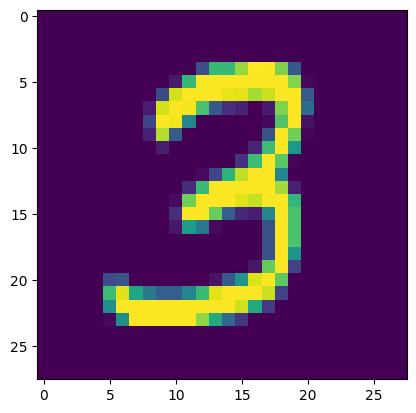

In [ ]:
plt.imshow(x_test[20].reshape(28,28))

In [ ]:
y_test[20]

np.int64(3)

In [ ]:
model.predict(x_test[20].reshape(1,784))

array([3])

In [ ]:
y_pred = model.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.6593886462882096

In [ ]:
model.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [ ]:
from sklearn.model_selection import GridSearchCV


In [ ]:
perms_grid = {
    'criterion' : ['gini','entropy'],
    'max_depth' : [1,2,3,4,5,6,7,None]
}


In [ ]:
grid = GridSearchCV(model,param_grid=perms_grid, cv=10, n_jobs=-1)

In [ ]:
grid.fit(x_train,y_train)

GridSearchCV(cv=10, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 2, 3, 4, 5, 6, 7, None]})

In [ ]:
grid.best_score_

np.float64(0.6736263736263737)

In [ ]:
grid.best_estimator_

DecisionTreeClassifier(criterion='entropy')

In [ ]:
from sklearn.datasets import *
import graphviz.backend as be
from dtreeviz import *
from IPython.display import Image, display_svg,SVG
from sklearn.tree import DecisionTreeClassifier

[Text(0.47190738341968913, 0.9615384615384616, 'x[569] <= 0.5\ngini = 0.899\nsamples = 913\nvalue = [89, 83, 114, 73, 98, 82, 95, 102, 89, 88]'),
 Text(0.20968264248704663, 0.8846153846153846, 'x[409] <= 3.5\ngini = 0.859\nsamples = 471\nvalue = [8, 58, 17, 37, 92, 34, 29, 93, 21, 82]'),
 Text(0.3407950129533679, 0.9230769230769231, 'True  '),
 Text(0.12613341968911918, 0.8076923076923077, 'x[406] <= 252.5\ngini = 0.772\nsamples = 133\nvalue = [6, 55, 5, 18, 3, 21, 6, 7, 9, 3]'),
 Text(0.09423575129533679, 0.7307692307692307, 'x[218] <= 5.5\ngini = 0.845\nsamples = 69\nvalue = [6, 5, 4, 12, 2, 20, 5, 7, 6, 2]'),
 Text(0.06930051813471502, 0.6538461538461539, 'x[151] <= 16.5\ngini = 0.856\nsamples = 47\nvalue = [1.0, 5.0, 4.0, 12.0, 2.0, 4.0, 5.0, 7.0, 6.0, 1.0]'),
 Text(0.04533678756476684, 0.5769230769230769, 'x[433] <= 5.0\ngini = 0.862\nsamples = 34\nvalue = [1, 5, 3, 1, 2, 3, 5, 7, 6, 1]'),
 Text(0.02072538860103627, 0.5, 'x[491] <= 42.0\ngini = 0.562\nsamples = 11\nvalue = [1, 0, 

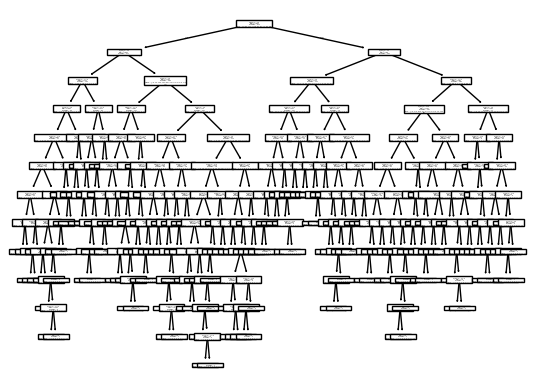

In [ ]:
from sklearn.tree import plot_tree
plot_tree(model)

In [ ]:
import dtreeviz

viz_model = dtreeviz.model(
    model,
    X_train=x_train,
    y_train=y_train,
    target_name='label',
    feature_names=df.columns[1:],
    class_names=[str(i) for i in range(10)]
)

viz_model.view(scale=2, fontname="DejaVu Sans")

In [ ]:
import dtreeviz

viz_model = dtreeviz.model(
    grid.best_estimator_,
    X_train=x_train,
    y_train=y_train,
    target_name='label',
    feature_names=df.columns[1:],
    class_names=[str(i) for i in range(10)]
)

viz_model.view(scale=2, fontname="DejaVu Sans")